In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.metrics import risk_metrics, drawdown_series

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

returns = pd.read_csv(config.PROCESSED_DIR / "returns_stocks.csv", index_col=0, parse_dates=True)
bench_ret = pd.read_csv(config.PROCESSED_DIR / "returns_benchmark.csv", index_col=0, parse_dates=True)

In [2]:
risk = risk_metrics(returns)
risk["sector"] = risk.index.map(config.SECTOR_MAP)
nifty = risk_metrics(bench_ret)

risk.to_csv(config.PROCESSED_DIR / "risk_metrics.csv")
print("NIFTY 50:\n", nifty.round(3).T)
risk.sort_values("sharpe", ascending=False).round(3).head(8)

NIFTY 50:
                 ^NSEI
cagr            0.096
ann_volatility  0.169
sharpe          0.169
sortino         0.226
max_drawdown   -0.384
var_95          0.015
cvar_95         0.025


,cagr,ann_volatility,sharpe,sortino,max_drawdown,var_95,cvar_95,sector
TITAN.NS,0.216,0.278,0.477,0.681,-0.417,0.025,0.040,Consumer
ICICIBANK.NS,0.197,0.291,0.402,0.572,-0.483,0.025,0.041,Banking & Financials
BAJFINANCE.NS,0.221,0.358,0.382,0.532,-0.624,0.032,0.054,Banking & Financials
JSWSTEEL.NS,0.210,0.335,0.381,0.531,-0.657,0.031,0.049,Metals
HCLTECH.NS,0.181,0.275,0.375,0.533,-0.448,0.026,0.040,IT
BAJAJ-AUTO.NS,0.173,0.264,0.368,0.521,-0.423,0.024,0.037,Auto
NESTLEIND.NS,0.148,0.224,0.336,0.501,-0.242,0.021,0.030,FMCG
POWERGRID.NS,0.161,0.259,0.332,0.476,-0.296,0.024,0.035,Energy & Utilities


In [3]:
Xc = returns - returns.mean()
cov_manual = (Xc.T @ Xc) / (len(returns) - 1)

print("Matches pandas .cov():", np.allclose(cov_manual, returns.cov()))
eig = np.linalg.eigvalsh(returns.cov().values)
print("Smallest eigenvalue:", eig.min().round(10), "(>= 0 means positive semi-definite)")
print("Condition number:", round(eig.max() / eig.min(), 1))

cov_ann = returns.cov() * config.TRADING_DAYS
corr = returns.corr()
corr.to_csv(config.PROCESSED_DIR / "correlation_matrix.csv")
cov_ann.to_csv(config.PROCESSED_DIR / "covariance_annual.csv")

Matches pandas .cov(): True
Smallest eigenvalue: 8.53911e-05 (>= 0 means positive semi-definite)
Condition number: 40.1


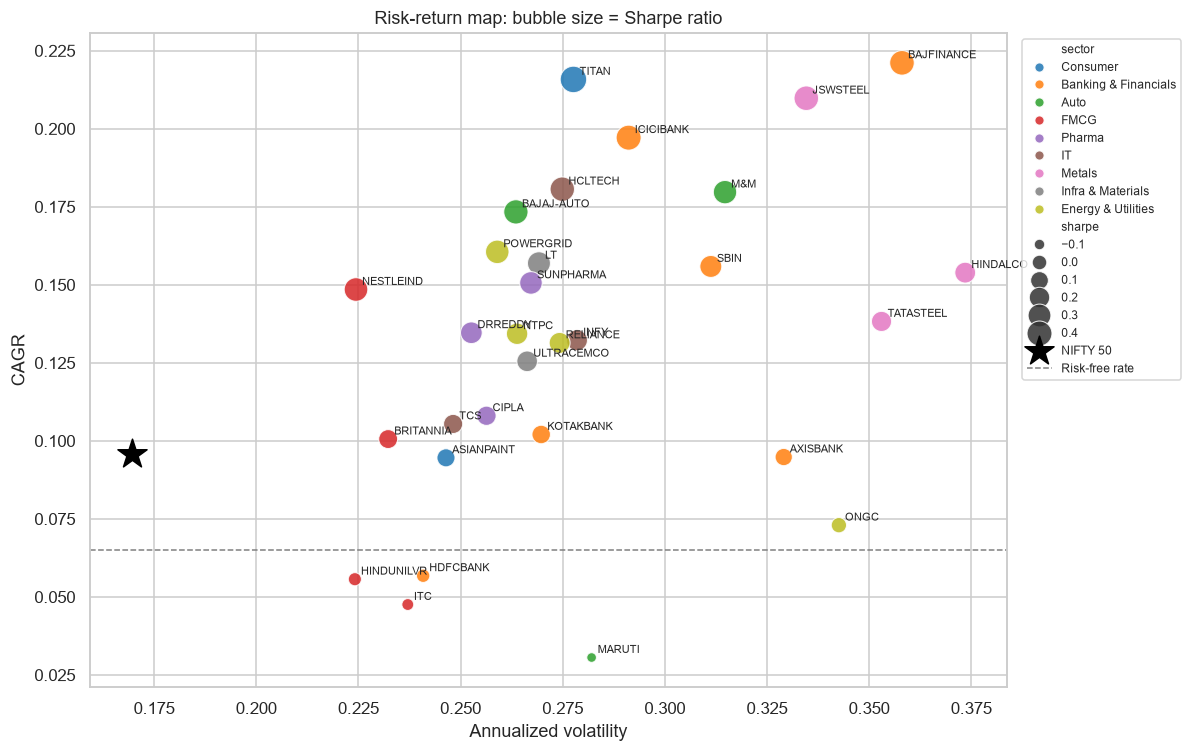

In [4]:
plot_df = risk.copy()
plt.figure(figsize=(11, 7))
sns.scatterplot(data=plot_df, x="ann_volatility", y="cagr", hue="sector",
                size="sharpe", sizes=(40, 300), palette="tab10", alpha=0.85)
plt.scatter(nifty["ann_volatility"], nifty["cagr"], marker="*", s=400,
            color="black", label="NIFTY 50", zorder=5)
for t, r in plot_df.iterrows():
    plt.annotate(t.replace(".NS", ""), (r["ann_volatility"], r["cagr"]),
                 fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.axhline(config.RISK_FREE_RATE, color="grey", ls="--", lw=1, label="Risk-free rate")
plt.xlabel("Annualized volatility"); plt.ylabel("CAGR")
plt.title("Risk-return map: bubble size = Sharpe ratio")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "04_risk_return_map.png", dpi=200, bbox_inches="tight")
plt.show()

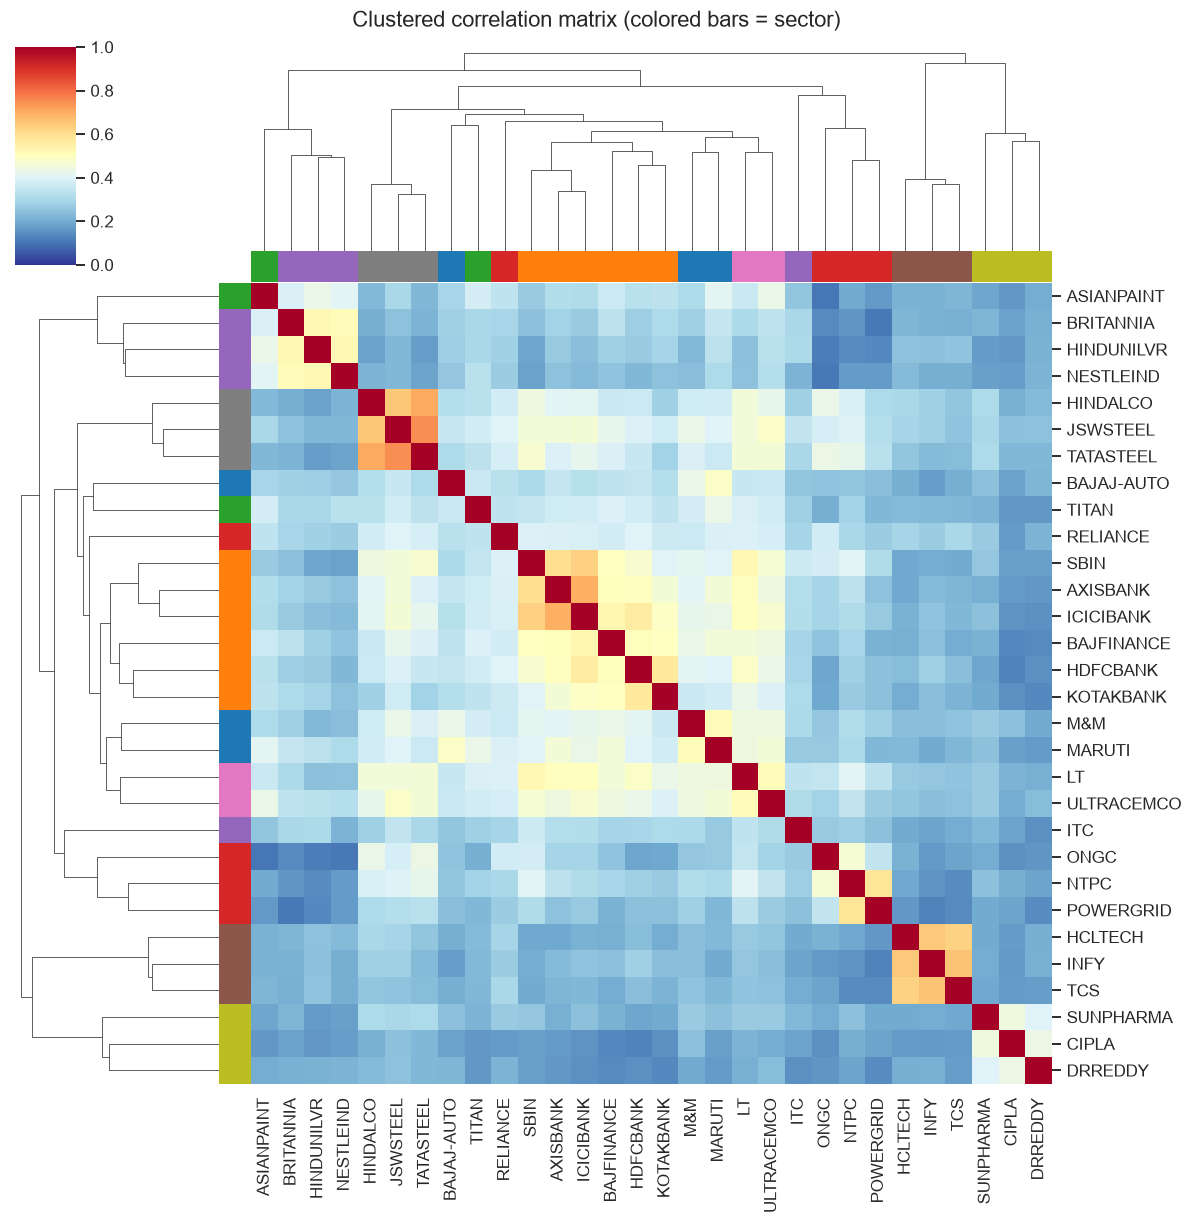

In [5]:
sector_colors = dict(zip(sorted(set(config.SECTOR_MAP.values())), sns.color_palette("tab10", 9)))
row_colors = [sector_colors[config.SECTOR_MAP[t]] for t in corr.index]

g = sns.clustermap(corr, cmap="RdYlBu_r", vmin=0, vmax=1, figsize=(11, 11),
                   row_colors=row_colors, col_colors=row_colors,
                   xticklabels=[t.replace(".NS", "") for t in corr.columns],
                   yticklabels=[t.replace(".NS", "") for t in corr.index])
g.fig.suptitle("Clustered correlation matrix (colored bars = sector)", y=1.01)
g.savefig(config.FIG_DIR / "05_correlation_clustermap.png", dpi=200, bbox_inches="tight")
plt.show()

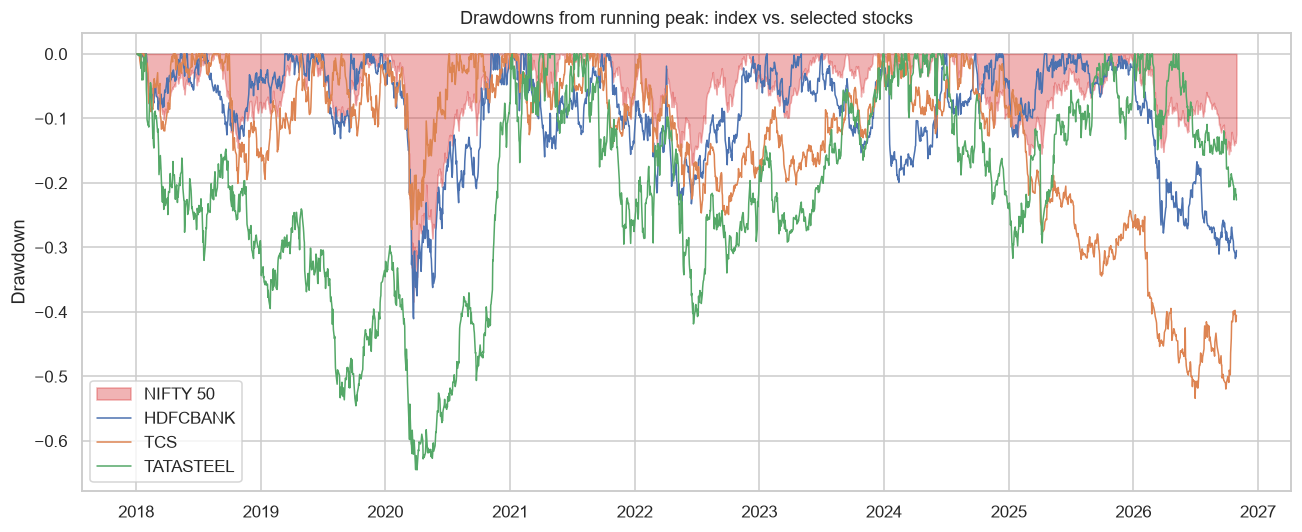

In [6]:
dd = drawdown_series(returns)
dd_bench = drawdown_series(bench_ret).iloc[:, 0]

plt.figure(figsize=(12, 5))
plt.fill_between(dd_bench.index, dd_bench, 0, color="#d62728", alpha=0.35, label="NIFTY 50")
for t in ["HDFCBANK.NS", "TCS.NS", "TATASTEEL.NS"]:
    plt.plot(dd.index, dd[t], lw=1, label=t.replace(".NS", ""))
plt.title("Drawdowns from running peak: index vs. selected stocks")
plt.ylabel("Drawdown"); plt.legend()
plt.tight_layout()
plt.savefig(config.FIG_DIR / "06_drawdowns.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
# ---------- Power BI exports ----------
risk.rename_axis("ticker").reset_index().to_csv(
    config.POWERBI_DIR / "risk_metrics.csv", index=False
)

corr_long = corr.stack().reset_index()
corr_long.columns = ["stock_a", "stock_b", "correlation"]
corr_long.to_csv(config.POWERBI_DIR / "correlation_long.csv", index=False)

# ---------- Conclusion numbers ----------
mask = ~np.eye(len(corr), dtype=bool)

sec = pd.Series(config.SECTOR_MAP).reindex(corr.index)
codes = pd.factorize(sec)[0]
same = codes[:, None] == codes[None, :]

print("Avg pairwise correlation (all):", round(corr.values[mask].mean(), 3))
print("Avg correlation, same sector:", round(corr.values[mask & same].mean(), 3))
print("Avg correlation, different sector:", round(corr.values[mask & ~same].mean(), 3))
print("Best Sharpe:", risk["sharpe"].idxmax(), round(risk["sharpe"].max(), 2))
print("Worst max drawdown:", risk["max_drawdown"].idxmin(), round(risk["max_drawdown"].min(), 3))
print("NIFTY 50 Sharpe:", round(nifty["sharpe"].iloc[0], 2), "| max DD:", round(nifty["max_drawdown"].iloc[0], 3))
print("Stocks with Sharpe above NIFTY:", (risk["sharpe"] > nifty["sharpe"].iloc[0]).sum(), "of 30")
print("CVaR/VaR ratio (avg):", round((risk["cvar_95"] / risk["var_95"]).mean(), 2))

Avg pairwise correlation (all): 0.302
Avg correlation, same sector: 0.494
Avg correlation, different sector: 0.282
Best Sharpe: TITAN.NS 0.48
Worst max drawdown: M&M.NS -0.723
NIFTY 50 Sharpe: 0.17 | max DD: -0.384
Stocks with Sharpe above NIFTY: 19 of 30
CVaR/VaR ratio (avg): 1.56


## Conclusion

Average pairwise correlation is **0.30**: **0.49** within sectors versus **0.28** across sectors, so diversifying across sectors reduces risk more than adding stocks within one sector. **TITAN** has the best Sharpe ratio (**0.48**) against **0.17** for NIFTY 50, and **19 of 30** stocks beat the index on risk-adjusted return (inflated by survivorship bias, since the universe is today's large-caps). The worst drawdown is **−72%** for **M&M** versus **−38%** for the index. CVaR averages **1.56×** VaR (≈1.25× under a normal distribution), confirming heavier tail losses than volatility suggests.

**Next:** PCA to find the hidden factors behind these correlations.